# Validating the series your model has never met

A local adaptation of Cerqueira, Oliveira and Roque (2026), [arXiv:2611.08252v1](https://arxiv.org/abs/2611.08252v1). The companion article is `post.md`. Both documents share every narrative heading after Setup and Utils.

# Setup

Run from this notebook's directory. Install `requirements.txt` into a Python 3.12 kernel and select it in Jupyter. Download the public [Hospital Dataset v2](https://zenodo.org/records/4656014) ZIP separately into `data/`, extract `hospital_dataset.tsf`, and keep the supplied checksum. Data are CC BY 4.0, originally from R's expsmooth package; cite Godahewa et al., *Monash Time Series Forecasting Archive* (2021).

The delivered default is **replay**: Run All recomputes metrics and assets from the retained, genuinely trained experiment. It makes no new training-speed measurement. To train afresh, change `CFG.mode` to `"live"` (or set `SERIESCV_MODE=live` before launch). Live fitting writes a new timestamped run and never fills missing replay evidence with new training. No repository helper import is needed. The complete run and source cache must accompany a copied replay notebook.

In [1]:
from datetime import datetime
from pathlib import Path
from zoneinfo import ZoneInfo
import hashlib
import importlib.metadata
import json
import os
import platform
import resource
import sys
import tempfile
import time

os.environ.setdefault("MPLCONFIGDIR", str(Path(tempfile.gettempdir()) / "seriescv-mpl"))
os.environ.setdefault("OPENBLAS_NUM_THREADS", "1")

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import Image, Markdown, display


Matplotlib is building the font cache; this may take a moment.


These imports separate standard-library utilities from numerical, plotting and notebook libraries. NumPy (`np`) owns arrays; Pandas (`pd`) organizes evidence; PyTorch trains the two neural models. `display`, `Image` and `Markdown` show the exact exported PNGs and their readings. Matplotlib's Agg backend renders files consistently without a GUI.

In [2]:
class CFG:
    mode = os.environ.get("SERIESCV_MODE", "replay")
    data_folder = Path("data")
    graph_folder = Path("graphs")
    timezone = "Europe/Amsterdam"
    execution_started_at = datetime.now(ZoneInfo(timezone))
    execution_date = execution_started_at.strftime("%d%m")
    run_folder = Path(os.environ.get("SERIESCV_RUN", json.loads(Path("latest-run.json").read_text())["path"] if Path("latest-run.json").exists() else "runs/missing-run"))
    source_sha256 = "b84c2d28f5154958cb31229a8db1b79eaba9b2307b477c02475eee698ed176e1"
    architectures = ["Ridge", "MLP", "GRU"]
    regularization = {"Ridge": [0.1, 10.0], "MLP": [0.0001, 0.01], "GRU": [0.0001, 0.01]}
    seeds = [123, 456, 789]
    rhos = [0.7, 1.0]
    context = 12
    horizon = 12
    in_end = 60
    epochs = 40
    study_series = 120
    pilot_series = 24
    bootstrap_reps = 2000
    compute_budget_seconds = 1200
    rss_limit_bytes = 8 * 2**30
    tie_tolerance = 1e-10
    img_dim1, img_dim2 = 9.5, 6.5
    export_dpi = 200
    colors = {"Time holdout": "#2379a8", "Series holdout": "#c78543", "Series 5-fold": "#6b5696"}
    packages = ["numpy", "pandas", "matplotlib", "torch", "nbformat", "nbclient", "ipykernel"]

assert CFG.mode in ("live", "replay")
torch.set_num_threads(1)
torch.use_deterministic_algorithms(True)
plt.style.use("seaborn-v0_8")
plt.rcParams["figure.figsize"] = (CFG.img_dim1, CFG.img_dim2)


CFG centralizes every adjustable setting. The date is captured once in Amsterdam time as day/month (`ddmm`); full timestamps identify runs. CPU training uses one thread and deterministic algorithms. Seeds identify repeated partitions of one dataset, not independent datasets. The plotting style is included with Matplotlib; seaborn is unnecessary.

# Utils

Project-specific implementation is embedded here, grouped by purpose. The narrative below calls these helpers rather than importing repository code.

## Data and protocol

In [3]:
def json_write(path, obj):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_text(json.dumps(obj, indent=2, allow_nan=False) + "\n")


def digest(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()


def read_panel(folder):
    path = Path(folder) / "hospital_dataset.tsf"
    if digest(path) != CFG.source_sha256:
        raise ValueError("Source TSF checksum mismatch")
    rows = []
    for line in path.read_text(encoding="cp1252").splitlines():
        if not line or line.startswith(("#", "@")):
            continue
        name, start, values = line.split(":", 2)
        rows.append((name, start, np.asarray(values.split(","), dtype=float)))
    assert len(rows) == 767 and len({r[0] for r in rows}) == 767
    assert all(len(r[2]) == 84 and np.isfinite(r[2]).all() for r in rows)
    assert all(r[1] == "2000-01-01 00-00-00" for r in rows)
    rows.sort(key=lambda r: hashlib.sha256(r[0].encode()).hexdigest())
    names = np.array([r[0] for r in rows])
    panel = np.stack([r[2] for r in rows])
    return names, panel


def normalize_context(x):
    center = x.mean(axis=1, keepdims=True)
    scale = np.maximum(x.std(axis=1, keepdims=True, ddof=0), 1.0)
    return (x - center) / scale, center, scale


def training_windows(development, ids, end):
    assert end <= development.shape[1] <= CFG.in_end
    assert CFG.context + CFG.horizon <= end
    origins = range(CFG.context, end - CFG.horizon + 1)
    x = np.stack([development[i, t-CFG.context:t] for i in ids for t in origins])
    y = np.stack([development[i, t:t+CFG.horizon] for i in ids for t in origins])
    xn, center, scale = normalize_context(x)
    return xn, (y-center)/scale


def protocol(ids, seed, rho):
    order = np.random.default_rng(seed).permutation(ids)
    n = int(np.floor(rho * len(ids)))
    known, unseen = order[:n], order[n:]
    assert not set(known) & set(unseen)
    rng = np.random.default_rng(seed + 9000)
    shuffle = rng.permutation(known)
    k = int(np.floor(0.7 * len(known)))
    folds = {"Time holdout": [(known, known)],
             "Series holdout": [(shuffle[:k], shuffle[k:])],
             "Series 5-fold": []}
    for val in np.array_split(shuffle, 5):
        train = np.array([i for i in known if i not in set(val)])
        folds["Series 5-fold"].append((train, val))
    for method, pairs in folds.items():
        for train, val in pairs:
            assert len(train) and len(val)
            if method != "Time holdout":
                assert not set(train) & set(val)
    return known, unseen, folds


def check_budget(started, prior=0.0):
    elapsed = time.monotonic() - started + prior
    rss = resource.getrusage(resource.RUSAGE_SELF).ru_maxrss
    rss_bytes = rss if sys.platform == "darwin" else rss * 1024
    if elapsed > CFG.compute_budget_seconds or rss_bytes > CFG.rss_limit_bytes:
        raise RuntimeError(f"Compute/resource guard: {elapsed:.1f}s, RSS {rss_bytes/2**30:.2f} GiB")

These helpers verify source hashes, construct context-only normalized windows and enforce both temporal and series membership rules. A training window's targets must end by its declared cutoff; context standard deviation has a floor of one count.

## Global forecasters

In [4]:
class TinyNetwork(torch.nn.Module):
    def __init__(self, arch):
        super().__init__()
        self.arch = arch
        if arch == "MLP":
            self.net = torch.nn.Sequential(torch.nn.Linear(12, 32), torch.nn.ReLU(),
                                           torch.nn.Linear(32, 12))
        else:
            self.gru = torch.nn.GRU(1, 8, batch_first=True)
            self.head = torch.nn.Linear(8, 12)

    def forward(self, x):
        if self.arch == "MLP":
            return self.net(x)
        _, hidden = self.gru(x.unsqueeze(-1))
        return self.head(hidden[-1])


class GlobalForecaster:
    def __init__(self, arch, reg, seed):
        self.arch, self.reg, self.seed = arch, float(reg), int(seed)

    def fit(self, x, y, started, prior):
        if self.arch == "Ridge":
            design = np.column_stack([np.ones(len(x)), x])
            penalty = np.eye(design.shape[1]) * self.reg
            penalty[0, 0] = 0.0
            self.coef = np.linalg.solve(design.T @ design + penalty, design.T @ y)
        else:
            torch.manual_seed(self.seed)
            self.net = TinyNetwork(self.arch)
            tx = torch.as_tensor(x, dtype=torch.float32)
            ty = torch.as_tensor(y, dtype=torch.float32)
            optimizer = torch.optim.Adam(self.net.parameters(), lr=0.01, weight_decay=self.reg)
            self.net.train()
            for epoch in range(CFG.epochs):
                optimizer.zero_grad()
                loss = torch.nn.functional.mse_loss(self.net(tx), ty)
                if not torch.isfinite(loss):
                    raise ValueError("Non-finite training objective")
                loss.backward()
                optimizer.step()
                if epoch % 10 == 0:
                    check_budget(started, prior)
            self.net.eval()
        return self

    def predict(self, raw_x):
        x, center, scale = normalize_context(raw_x)
        if self.arch == "Ridge":
            pred = np.column_stack([np.ones(len(x)), x]) @ self.coef
        else:
            with torch.no_grad():
                pred = self.net(torch.as_tensor(x, dtype=torch.float32)).numpy().astype(float)
        result = pred * scale + center
        if not np.isfinite(result).all():
            raise ValueError("Non-finite predictions")
        return result

    def weights(self):
        if self.arch == "Ridge":
            return {"coef": self.coef}
        return {key: value.detach().numpy() for key, value in self.net.state_dict().items()}


def fit_logged(development, ids, end, arch, reg, seed, logs, tag, started, prior):
    check_budget(started, prior)
    tic = time.monotonic()
    x, y = training_windows(development, ids, end)
    model = GlobalForecaster(arch, reg, seed).fit(x, y, started, prior)
    logs.append(dict(tag=tag, architecture=arch, regularization=float(reg), seed=int(seed),
                     training_series=len(ids), training_windows=len(x), target_end=int(end),
                     seconds=time.monotonic()-tic, status="complete"))
    if len(logs) % 36 == 0:
        print(f"  {len(logs)} fits complete", flush=True)
    return model


def choose_index(values):
    values = np.asarray(values, dtype=float)
    if not np.isfinite(values).all():
        raise ValueError("Non-finite selection score")
    return int(np.flatnonzero(values <= values.min() + CFG.tie_tolerance)[0])


def tune_refit(development, ids, end, arch, split_seed, fold_id, final, logs,
               tag, started, prior):
    a = CFG.architectures.index(arch)
    inner_stage, refit_stage = (0, 1) if final else (10+fold_id, 30+fold_id)
    inner_seed = 100000 + split_seed*100 + inner_stage*10 + a
    refit_seed = 100000 + split_seed*100 + refit_stage*10 + a
    inner_end = end - CFG.horizon
    assert inner_end + CFG.horizon == end <= CFG.in_end
    scores = []
    for reg in CFG.regularization[arch]:
        model = fit_logged(development, ids, inner_end, arch, reg, inner_seed,
                           logs, tag+"/tune", started, prior)
        raw = development[ids, inner_end-CFG.context:inner_end]
        truth = development[ids, inner_end:inner_end+CFG.horizon]
        scores.append(float(np.abs(model.predict(raw)-truth).mean()))
    reg = CFG.regularization[arch][choose_index(scores)]
    model = fit_logged(development, ids, end, arch, reg, refit_seed, logs,
                       tag+"/refit", started, prior)
    return model, dict(regularization=reg, inner_mae=scores, seed=refit_seed,
                       inner_seed=inner_seed)

The direct ridge, MLP and GRU share 12-step inputs/outputs. Inner temporal validation chooses regularization; refitting uses only the allowed training prefix. Every fit logs seeds, training size and elapsed CPU time. Normalized MSE is the training objective, while validation uses raw-count MAE.

## Experiment and retained evidence

In [5]:
def select_on_development(development, names, seeds, rhos, root, started, prior):
    assert development.shape == (len(names), CFG.in_end)
    logs, audits, locks, models, cv_raw = [], [], {}, {}, {}
    for rho in rhos:
        for seed in seeds:
            key = f"rho{rho:.1f}_seed{seed}"
            known, unseen, folds = protocol(np.arange(len(names)), seed, rho)
            q = float(np.abs(development[known, 12:60]-development[known, :48]).mean())
            if not np.isfinite(q) or q <= 0:
                raise ValueError("Global MASE denominator must be positive")
            estimates, tuning = {}, {}
            print(f"Selecting {key}: {len(known)} known, {len(unseen)} unseen", flush=True)
            for method, pairs in folds.items():
                estimates[method] = []
                for arch in CFG.architectures:
                    losses = []
                    for fold_id, (train, val) in enumerate(pairs):
                        tag = f"{key}/{method}/{arch}/fold{fold_id}"
                        model, chosen = tune_refit(development, train, 48, arch, seed,
                                                  fold_id, False, logs, tag, started, prior)
                        pred = model.predict(development[val, 36:48])
                        truth = development[val, 48:60]
                        losses.append(float(np.abs(pred-truth).mean()/q))
                        array_key = f"{key}_{method}_{arch}_{fold_id}".replace(" ", "_")
                        cv_raw[array_key+"_prediction"] = pred
                        cv_raw[array_key+"_truth"] = truth
                        cv_raw[array_key+"_validation_ids"] = names[val]
                        audits.append(dict(key=key, method=method, architecture=arch,
                                           fold=fold_id, training_ids=names[train].tolist(),
                                           validation_ids=names[val].tolist(), fit_target_end=48,
                                           validation_start=48, validation_end=60,
                                           chosen=chosen, fold_mase=losses[-1]))
                    estimates[method].append(float(np.mean(losses)))
            for arch in CFG.architectures:
                model, chosen = tune_refit(development, known, 60, arch, seed, 0, True,
                                          logs, f"{key}/common_final/{arch}", started, prior)
                models[(key, arch)] = model
                tuning[arch] = chosen
            selected = {m: CFG.architectures[choose_index(v)] for m, v in estimates.items()}
            locks[key] = dict(rho=rho, seed=seed, q=q, known_ids=names[known].tolist(),
                              unseen_ids=names[unseen].tolist(), estimates=estimates,
                              selected=selected, final_tuning=tuning)
    json_write(root/"selection-lock.json", locks)
    json_write(root/"split-audit.json", audits)
    pd.DataFrame(logs).to_csv(root/"fits.csv", index=False)
    np.savez_compressed(root/"cv-predictions.npz", **cv_raw)
    weights = {}
    for (key, arch), model in models.items():
        for parameter, value in model.weights().items():
            weights[f"{key}_{arch}_{parameter}"] = value
    np.savez_compressed(root/"final-weights.npz", **weights)
    return locks, models, logs


def run_experiment(panel, names, seeds, rhos, output, prior=0.0):
    output = Path(output)
    output.mkdir(parents=True, exist_ok=False)
    started = time.monotonic()
    status = dict(status="running", started_at=datetime.now(ZoneInfo(CFG.timezone)).isoformat(),
                  source_sha256=CFG.source_sha256, ids=names.tolist(), seeds=list(seeds),
                  rhos=list(rhos), configuration=configuration())
    json_write(output/"run.json", status)
    try:
        development = panel[:, :CFG.in_end].copy()
        locks, models, logs = select_on_development(development, names, seeds, rhos,
                                                   output, started, prior)
        # The complete selection lock is on disk before any final target is scored.
        selection_hash = digest(output/"selection-lock.json")
        origins = np.arange(60, 73)
        truth = np.stack([panel[:, t:t+12] for t in origins], axis=1)
        predictions = {}
        for key in locks:
            for arch in CFG.architectures:
                predictions[f"{key}_{arch}"] = np.stack(
                    [models[(key, arch)].predict(panel[:, t-12:t]) for t in origins], axis=1)
            predictions[f"{key}_Seasonal naive"] = np.stack(
                [panel[:, t-12:t] for t in origins], axis=1)
        np.savez_compressed(output/"predictions.npz", truth=truth, ids=names,
                            origins=origins, **predictions)
        status.update(status="complete", seconds=time.monotonic()-started,
                      fit_count=len(logs), selection_lock_sha256=selection_hash,
                      python=platform.python_version(), platform=platform.platform(),
                      packages={p:importlib.metadata.version(p) for p in CFG.packages})
        json_write(output/"run.json", status)
        return output
    except Exception as exc:
        status.update(status="failed", error=repr(exc), seconds=time.monotonic()-started)
        json_write(output/"run.json", status)
        raise


def configuration():
    return dict(architectures=CFG.architectures, regularization=CFG.regularization,
                context=12, horizon=12, in_end=60, epochs=CFG.epochs,
                normalization="context mean/std(ddof=0), std floor=1",
                objective="normalized-target MSE", threads=torch.get_num_threads(),
                backend="CPU", tie_tolerance=CFG.tie_tolerance)

Selection receives only the first 60 months. It writes every selector and hyperparameter to disk before final targets are scored. Final models are shared across validation procedures; raw CV and deployment predictions are retained separately. A failure records an explicit run status.

## Metrics and uncertainty

In [6]:
def analyze_run(root):
    root = Path(root)
    run = json.loads((root/"run.json").read_text())
    assert run["status"] == "complete"
    assert run["source_sha256"] == CFG.source_sha256
    assert run["configuration"] == configuration(), "Replay configuration mismatch"
    assert digest(root/"selection-lock.json") == run["selection_lock_sha256"]
    locks = json.loads((root/"selection-lock.json").read_text())
    with np.load(root/"predictions.npz", allow_pickle=False) as saved:
        ids, truth = saved["ids"].copy(), saved["truth"].copy()
        assert truth.shape == (len(ids), 13, 12) and np.isfinite(truth).all()
        predictions = {k:saved[k].copy() for k in saved.files if k not in ("ids","truth","origins")}
    rows, details, per_series = [], [], []
    for key, lock in locks.items():
        losses = []
        for arch in CFG.architectures:
            errors = np.abs(predictions[f"{key}_{arch}"]-truth)/lock["q"]
            assert np.isfinite(errors).all()
            losses.append(float(errors.mean()))
            for method, estimates in lock["estimates"].items():
                details.append(dict(key=key, rho=lock["rho"], seed=lock["seed"],
                                     method=method, architecture=arch,
                                     estimated_mase=estimates[CFG.architectures.index(arch)],
                                     true_mase=losses[-1]))
        oracle_index = choose_index(losses)
        naive = float(np.abs(predictions[f"{key}_Seasonal naive"]-truth).mean()/lock["q"])
        for method, estimates in lock["estimates"].items():
            selected = lock["selected"][method]
            assert selected == CFG.architectures[choose_index(estimates)]
            index = CFG.architectures.index(selected)
            errors = np.abs(predictions[f"{key}_{selected}"]-truth)/lock["q"]
            series_loss = errors.mean(axis=(1,2))
            known = np.isin(ids, lock["known_ids"])
            rows.append(dict(key=key, rho=lock["rho"], seed=lock["seed"], method=method,
                             selected=selected, oracle=CFG.architectures[oracle_index],
                             mase=losses[index], mapee=float(np.abs(np.array(estimates)-losses).mean()),
                             optimism=float((np.array(estimates)<losses).mean()),
                             selection_hit=int(index==oracle_index), regret=losses[index]-min(losses),
                             known_mase=float(series_loss[known].mean()),
                             unseen_mase=float(series_loss[~known].mean()) if (~known).any() else np.nan,
                             seasonal_naive=naive))
            for i, name in enumerate(ids):
                per_series.append(dict(rho=lock["rho"], seed=lock["seed"], method=method,
                                       series_id=name, known=bool(known[i]), mase=float(series_loss[i])))
    scores, details, per_series = pd.DataFrame(rows), pd.DataFrame(details), pd.DataFrame(per_series)
    summary = scores.groupby(["rho","method"],sort=False).agg(
        MASE=("mase","mean"), MAPEE=("mapee","mean"), Overoptimism=("optimism","mean"),
        Selection_hits=("selection_hit","sum"), Regret=("regret","mean"),
        Known_MASE=("known_mase","mean"), Unseen_MASE=("unseen_mase","mean")).reset_index()
    paired = per_series.query("rho == 0.7").pivot(index=["series_id","seed"],columns="method",values="mase")
    delta = paired["Series 5-fold"]-paired["Time holdout"]
    by_series = delta.groupby(level="series_id").mean().to_numpy()
    rng = np.random.default_rng(20261106)
    bootstrap = by_series[rng.integers(0,len(by_series),(CFG.bootstrap_reps,len(by_series)))].mean(axis=1)
    interval = dict(delta=float(by_series.mean()), low=float(np.quantile(bootstrap,.025)),
                    high=float(np.quantile(bootstrap,.975)), series_clusters=len(by_series),
                    bootstrap_reps=CFG.bootstrap_reps,
                    interpretation="conditional series bootstrap; fixed models/selectors/Q; shared calendar shocks and refitting uncertainty excluded")
    return dict(run=run, locks=locks, scores=scores, details=details, per_series=per_series,
                summary=summary, primary=interval, predictions=predictions, truth=truth, ids=ids)


def validate_evidence(root, result):
    locks, names = result["locks"], result["ids"]
    source_names, source_panel = read_panel(CFG.data_folder)
    source_lookup = {name:i for i,name in enumerate(source_names)}
    original = source_panel[[source_lookup[name] for name in names]]
    expected_truth = np.stack([original[:,t:t+12] for t in range(60,73)],axis=1)
    np.testing.assert_array_equal(result["truth"],expected_truth)
    audits = json.loads((Path(root)/"split-audit.json").read_text())
    reductions = {}
    with np.load(Path(root)/"cv-predictions.npz",allow_pickle=False) as cv:
        for fold in audits:
            known = set(locks[fold["key"]]["known_ids"])
            assert set(fold["training_ids"]) <= known and set(fold["validation_ids"]) <= known
            assert fold["fit_target_end"] <= fold["validation_start"] == 48
            if fold["method"] != "Time holdout":
                assert not set(fold["training_ids"]) & set(fold["validation_ids"])
            key=f"{fold['key']}_{fold['method']}_{fold['architecture']}_{fold['fold']}".replace(" ","_")
            truth=source_panel[[source_lookup[name] for name in fold["validation_ids"]],48:60]
            np.testing.assert_array_equal(cv[key+"_truth"],truth)
            np.testing.assert_array_equal(cv[key+"_validation_ids"],fold["validation_ids"])
            loss=float(np.abs(cv[key+"_prediction"]-truth).mean()/locks[fold["key"]]["q"])
            np.testing.assert_allclose(loss,fold["fold_mase"],rtol=1e-10,atol=1e-10)
            reductions.setdefault((fold["key"],fold["method"],fold["architecture"]),[]).append(loss)
    for (key,method,arch),values in reductions.items():
        estimate=locks[key]["estimates"][method][CFG.architectures.index(arch)]
        np.testing.assert_allclose(np.mean(values),estimate,rtol=1e-10,atol=1e-10)
    for lock in locks.values():
        assert set(lock["known_ids"]).isdisjoint(lock["unseen_ids"])
        assert set(lock["known_ids"]) | set(lock["unseen_ids"]) == set(names)
        prefix=source_panel[[source_lookup[name] for name in lock["known_ids"]],:60]
        q=float(np.abs(prefix[:,12:]-prefix[:,:-12]).mean())
        np.testing.assert_allclose(q,lock["q"],rtol=1e-10,atol=1e-10)
    assert len(result["scores"]) == len(locks)*3
    assert result["scores"].regret.min() >= -CFG.tie_tolerance
    return dict(status="passed", folds=len(audits), conditions=len(locks),
                scored_procedures=len(result["scores"]), source_hash_verified=True,
                selection_lock_hash_verified=True, series_and_temporal_boundaries=True,
                cv_losses_recomputed=True, cv_and_final_targets_match_source=True,
                global_denominators_recomputed=True)

These functions recompute global-scaled MASE and the five CV evaluation dimensions from saved predictions. Unequal series folds are averaged arithmetically. The paired series bootstrap keeps overlapping origins, horizons and split-seed contributions together, with fitted models, selections and Q fixed.

## Publication helpers

In [7]:
def save_visual(fig, number, kind, caption, reading, section, manifest):
    assert len(fig.axes) == 1, "Each asset must contain one graph or one table"
    prefix = "graph" if kind == "graph" else "tabler"
    path = CFG.graph_folder / f"{prefix}_{number:02d}_{CFG.execution_date}.png"
    if path.exists():
        archive = Path("render-archive") / CFG.execution_started_at.strftime("%Y%m%dT%H%M%S%f%z") / path.name
        archive.parent.mkdir(parents=True, exist_ok=True)
        if archive.exists():
            archive = archive.with_name(f"{time.time_ns()}-{archive.name}")
        archive.write_bytes(path.read_bytes())
    fig.savefig(path, dpi=CFG.export_dpi, bbox_inches="tight", facecolor="white")
    plt.close(fig)
    display(Image(filename=str(path)))
    display(Markdown(f"*{kind.title()} {number:02d}. {caption}*\n\n{reading}"))
    manifest.append(dict(number=f"{number:02d}", kind=kind, path=path.as_posix(),
                         caption=caption, alt=caption, reading=reading, section=section,
                         execution_started_at=CFG.execution_started_at.isoformat(),
                         source_run=str(CFG.run_folder), sha256=digest(path)))


def table_figure(frame, title):
    fig, ax = plt.subplots(figsize=(CFG.img_dim1, max(2.2, .55*len(frame)+1.1)))
    ax.axis("off")
    ax.set_title(title, pad=18, fontsize=13)
    shown = frame.copy()
    for col in shown:
        if pd.api.types.is_integer_dtype(shown[col]):
            shown[col] = shown[col].map(lambda x: str(int(x)))
        elif pd.api.types.is_numeric_dtype(shown[col]):
            decimals = 1 if col == "rho" else (4 if col in ("MASE","MAPEE","Regret") else 3)
            shown[col] = shown[col].map(lambda x: "N/A" if pd.isna(x) else f"{x:.{decimals}f}")
    table = ax.table(cellText=shown.values,colLabels=shown.columns,loc="center",cellLoc="center")
    table.auto_set_font_size(False)
    table.set_fontsize(9)
    table.scale(1,1.7)
    for (row,col),cell in table.get_celld().items():
        cell.set_facecolor("#dce8f2" if row==0 else ("#f1f4f7" if row%2 else "white"))
        cell.set_text_props(color="black")
    return fig


def publish_outputs(result, names, panel, section=None, manifest=None):
    CFG.graph_folder.mkdir(parents=True,exist_ok=True)
    manifest = [] if manifest is None else manifest
    if section is None or section == 'A small hospital panel':
        months=pd.date_range("2000-01-01",periods=84,freq="MS")
        fig,ax=plt.subplots();ax.plot(months[:60],panel[0,:60],color="#2379a8")
        ax.axvspan(months[60],months[-1],color="#ded8e8",alpha=.6,label="Final targets withheld from this view")
        ax.set(title=f"Study series {names[0]}: one example, chosen by ID",ylabel="Monthly counts")
        ax.legend();fig.autofmt_xdate()
        save_visual(fig,1,"graph","A deterministic example from the Hospital panel.",
                    "The final 24 months are reserved for deployment scoring. This single series illustrates the task; it does not determine the aggregate ranking.",
                    "A small hospital panel",manifest)
    if section is None or section == 'Two boundaries, one forecast':
        fig,ax=plt.subplots();mask=np.zeros((12,84));mask[:8,:48]=1;mask[8:,48:60]=2;mask[:,60:]=3
        ax.imshow(mask,aspect="auto",cmap=matplotlib.colors.ListedColormap(["#eeeeee","#78a6d0","#e8b568","#ad8ec0"]),vmin=0,vmax=3)
        ax.set(title="Series-wise outer fold: separate IDs and future targets",xlabel="Month index (0-based)",ylabel="Illustrative series row")
        for x in (36,48,60):ax.axvline(x-.5,color="white",linewidth=2)
        ax.text(10,2,"FIT",weight="bold");ax.text(49,10,"CV",weight="bold");ax.text(63,5,"FINAL",weight="bold")
        save_visual(fig,2,"graph","Illustrative split mask, not a data-value heatmap.",
                    "Blue history fits a model; orange targets belong to different series. Purple targets are untouched until all selectors are locked. Held-out series still supply past context when forecast.",
                    "Two boundaries, one forecast",manifest)
    if section is None or section == 'Three global forecasters':
        scope=pd.DataFrame({"Component":["Panels","Forecast models","HPO options","CV procedures","Split seeds"],"Paper":["11","10 neural","20 trials","7","3"],"Local":["1 / 120 series","Ridge, MLP, GRU","2 per model","3","3"]})
        save_visual(table_figure(scope,"A local adaptation, not a benchmark replication"),3,"table",
                    "The local study deliberately narrows the paper's scope.",
                "The model pool and search are small enough for a laptop. Conclusions apply to this panel and candidate pool, not to the paper's full benchmark.",
                    "Three global forecasters",manifest)
    if section is None or section == 'Estimating error versus choosing a model':
        fig,ax=plt.subplots()
        d=result["details"].query("rho == 0.7")
        for method,color in CFG.colors.items():
            s=d[d.method==method];ax.scatter(s.estimated_mase,s.true_mase,label=method,color=color,s=48,alpha=.8)
        lo=min(d.estimated_mase.min(),d.true_mase.min());hi=max(d.estimated_mase.max(),d.true_mase.max())
        ax.plot([lo,hi],[lo,hi],"k--",linewidth=1);ax.set(xlabel="CV estimate (global MASE)",ylabel="Final loss (global MASE)",title="Estimating performance is a separate task (rho=0.7)");ax.legend()
        save_visual(fig,4,"graph","Each dot is one architecture, split seed and validation procedure.",
                    "The diagonal marks a perfect estimate. Above it, CV was optimistic. Closeness to the diagonal need not imply selecting the best model.",
                    "Estimating error versus choosing a model",manifest)
        summary=result["summary"][["rho","method","MASE","MAPEE","Overoptimism","Selection_hits","Regret"]].copy()
        summary.columns=["rho","CV","MASE","MAPEE","Optimism","Hits / 3","Regret"]
        save_visual(table_figure(summary,"Forecast loss and selection quality: three split seeds"),5,"table",
                    "Mean scores on one panel; hits use three split seeds, not three datasets.",
                    "Lower MASE, MAPEE and regret are better. Optimism is the fraction of the three candidate errors underestimated per seed. The oracle is restricted to the same final model pool.",
                    "Estimating error versus choosing a model",manifest)
    if section is None or section == 'Familiar series and new arrivals':
        s=result["scores"].query("rho == 0.7").pivot(index="seed",columns="method",values="mase")
        fig,ax=plt.subplots()
        for j,(method,color) in enumerate(list(CFG.colors.items())[1:]):
            ax.scatter(np.arange(len(s))+(j-.5)*.12,s[method]-s["Time holdout"],label=method,color=color,s=65)
        ax.set_xticks(np.arange(len(s)),s.index.astype(str))
        ax.axhline(0,color="black",linewidth=1);ax.set(xlabel="Split / training seed",ylabel="Selected-model MASE difference",title="Procedure minus time holdout: negative favors series-wise");ax.legend()
        p=result["primary"]
        save_visual(fig,6,"graph","Paired downstream differences at rho=0.7.",
                    f"Five-fold mean delta is {p['delta']:.4f}; its conditional series-bootstrap 95% interval is [{p['low']:.4f}, {p['high']:.4f}]. Models, selectors and Q stay fixed. Shared shocks and refitting uncertainty are excluded.",
                    "Familiar series and new arrivals",manifest)
        strata=result["scores"].query("rho == 0.7").groupby("method",sort=False)[["known_mase","unseen_mase"]].mean()
        fig,ax=plt.subplots();x=np.arange(len(strata))
        ax.bar(x-.18,strata.known_mase,width=.36,label="Known during fitting",color="#2379a8")
        ax.bar(x+.18,strata.unseen_mase,width=.36,label="Excluded from fitting",color="#c78543")
        ax.set_xticks(x,strata.index);ax.set(ylabel="Selected-model global MASE")
        ax.set_title("Different IDs, same deployment calendar (rho=0.7)",pad=48)
        ax.legend(loc="lower left",bbox_to_anchor=(0,1.01),ncol=2,fontsize=10)
        time_rows=result["scores"].query("rho == 0.7 and method == 'Time holdout'")
        harder=time_rows.loc[time_rows.unseen_mase>time_rows.known_mase,"seed"].astype(str).tolist()
        save_visual(fig,7,"graph","Known and unseen series are scored separately with the same Q.",
                f"The unseen stratum has higher mean loss in {len(harder)} of {len(time_rows)} time-holdout partitions (seeds: {', '.join(harder) or 'none'}). The aggregate bars hide that variation. These different series groups do not identify a causal penalty from exclusion; all strata share the run's Q.",
                    "Familiar series and new arrivals",manifest)
    if section is None or section == 'What this experiment cannot establish':
        fits=pd.read_csv(CFG.run_folder/"fits.csv")
        fits["procedure"]=fits.tag.map(lambda t:t.split("/")[1])
        timing=fits.groupby("procedure",sort=False).agg(Fits=("seconds","size"),Seconds=("seconds","sum"),Max_windows=("training_windows","max")).reset_index()
        timing["procedure"]=timing["procedure"].replace({"common_final":"Common final pool"})
        timing=timing.rename(columns={"procedure":"Procedure","Max_windows":"Max. windows"})
        save_visual(table_figure(timing,"Observed fitting work across all six seed/rho conditions"),8,"table",
                    "Logical fits and local CPU fitting time; common final models are trained once per condition.",
                    "Five-fold CV spends more fits and trains on fewer series per outer fit. These are whole-procedure comparisons, not isolated measurements of the effect of series separation.",
                    "What this experiment cannot establish",manifest)
    if section is None or section == "What this experiment cannot establish":
        for entry in manifest:
            entry["source_run"] = str(CFG.run_folder)
        json_write(Path("asset-manifest.json"),manifest)
        result["scores"].to_csv("scores.csv",index=False)
        result["summary"].to_csv("summary.csv",index=False)
        result["details"].to_csv("estimation-details.csv",index=False)
        result["per_series"].to_csv("per-series-losses.csv",index=False)
        json_write("primary-comparison.json",result["primary"])
    return manifest

Each exported file contains one graph or one table. A shared two-digit sequence uses graph_ or the requested tabler_ prefix and the execution date. Captions, readings, source-run identity and image hashes enter the manifest. The notebook displays those same PNG bytes.

# The series your model has never met

A global model can forecast a series whose history never contributed to parameter fitting. That is different from forecasting without a history: its recent observations are still context. This experiment asks whether withholding whole series during validation changes model selection. It is one small real-data adaptation, not the paper's full benchmark.

In [8]:
all_names, all_panel = read_panel(CFG.data_folder)
names = all_names[CFG.pilot_series:CFG.pilot_series+CFG.study_series]
panel = all_panel[CFG.pilot_series:CFG.pilot_series+CFG.study_series]
manifest = []
print(f"{len(names)} study series; {CFG.pilot_series} separate pilot series; {panel.shape[1]} months each")

120 study series; 24 separate pilot series; 84 months each


Series IDs are SHA-256 ordered before target inspection. The first 24 belong only to the pilot; the next 120 form the study panel. Both source length and finiteness are checked, so no error-dependent exclusions occur.

# A small hospital panel

The archive contains 767 monthly series spanning January 2000 to December 2006. Our 120-series subset has 84 observations per series. The final 24 months are untouched deployment targets. The first graph, exported below with the rest of the asset set, uses the first study ID rather than a favorable forecast example.

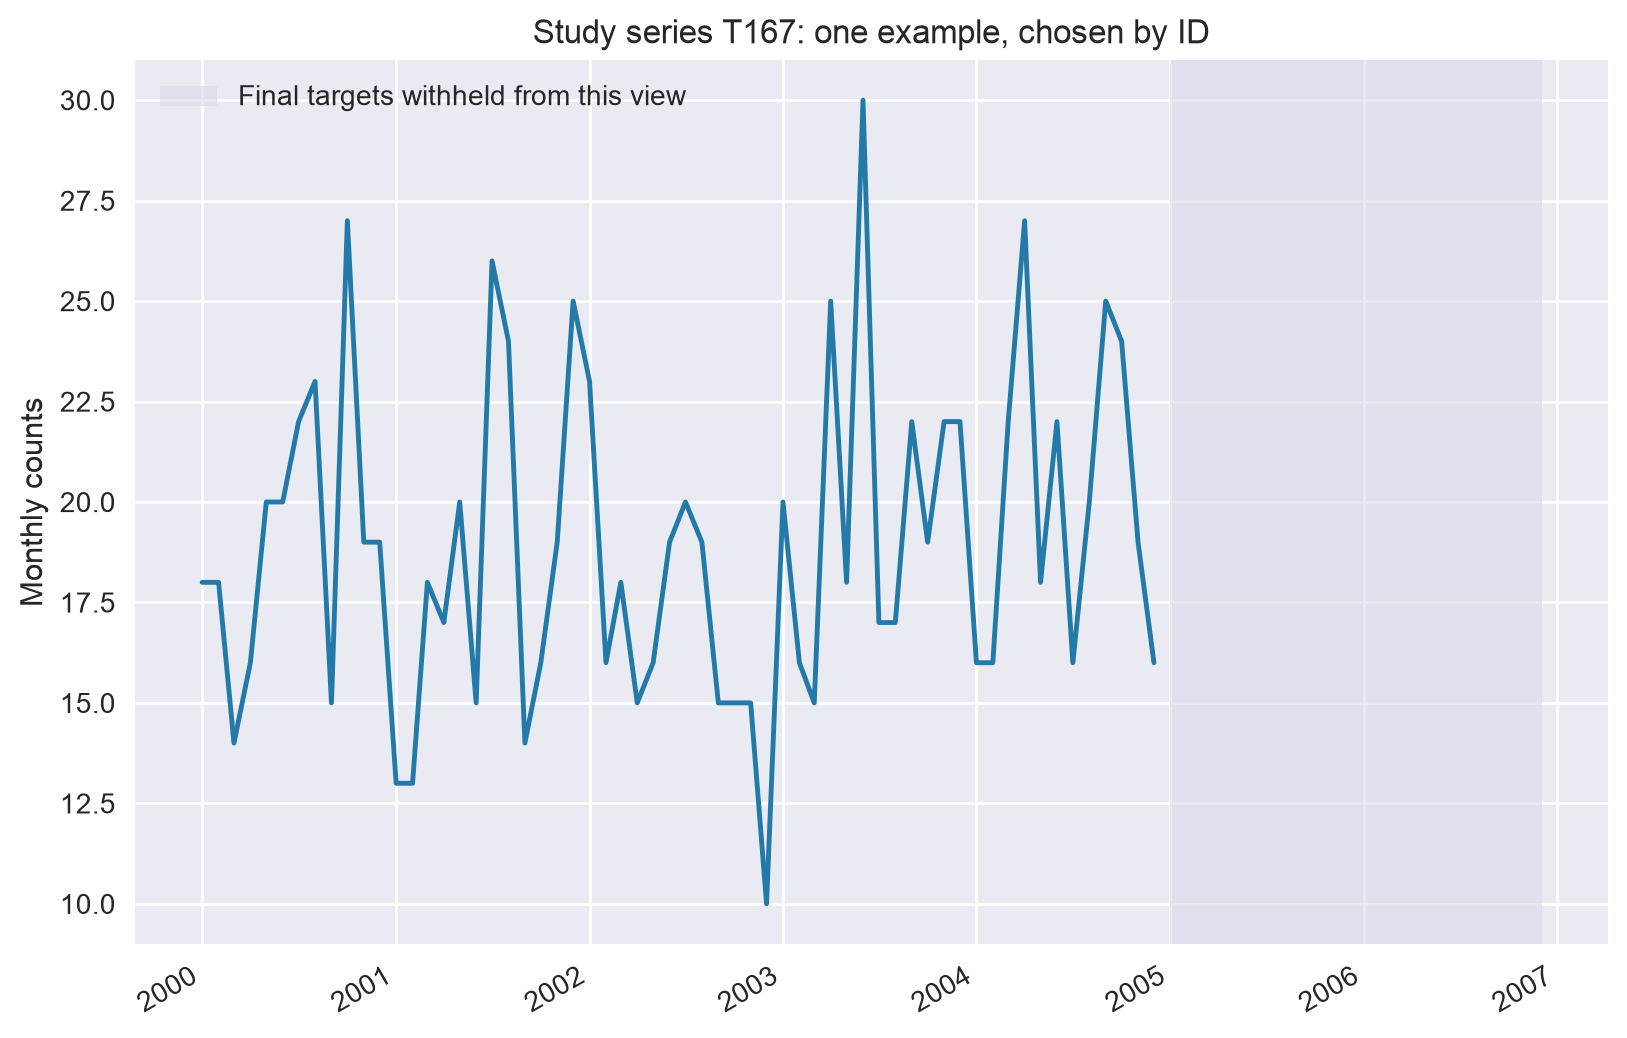

*Graph 01. A deterministic example from the Hospital panel.*

The final 24 months are reserved for deployment scoring. This single series illustrates the task; it does not determine the aggregate ranking.

In [9]:
manifest = publish_outputs(None, names, panel, "A small hospital panel", manifest)

This graph is an ID-selected illustration of the data, not a model-selection input. Its final-period values are displayed only after the frozen experiment has been defined; all fitting and tuning helpers receive the development prefix alone.

# Two boundaries, one forecast

Within the 60-month in-set, outer fitting ends at month index 48 and validates 48:60. Inner tuning fits through 36 and validates 36:48. A series-wise fold also excludes every validation series from fitting. With rho=0.7, 84 of the 120 series are known during development and 36 emerge only at deployment; rho=1 is the all-known control. At deployment the model predicts 12 months at each of 13 rolling origins. Overlap is intentional, and the error positions are not independent.

In [10]:
known, unseen, fold_examples = protocol(np.arange(len(names)), 123, 0.7)
print(f"Known: {len(known)}, unseen: {len(unseen)}")
print({method: [(len(tr),len(va)) for tr,va in folds] for method,folds in fold_examples.items()})

Known: 84, unseen: 36
{'Time holdout': [(84, 84)], 'Series holdout': [(58, 26)], 'Series 5-fold': [(67, 17), (67, 17), (67, 17), (67, 17), (68, 16)]}


Time holdout reuses series IDs across a temporal boundary. Series holdout and five-fold CV keep fitting and validation IDs disjoint, while preserving that same temporal boundary. Their training sizes, averaging and compute differ, so the comparison concerns whole procedures.

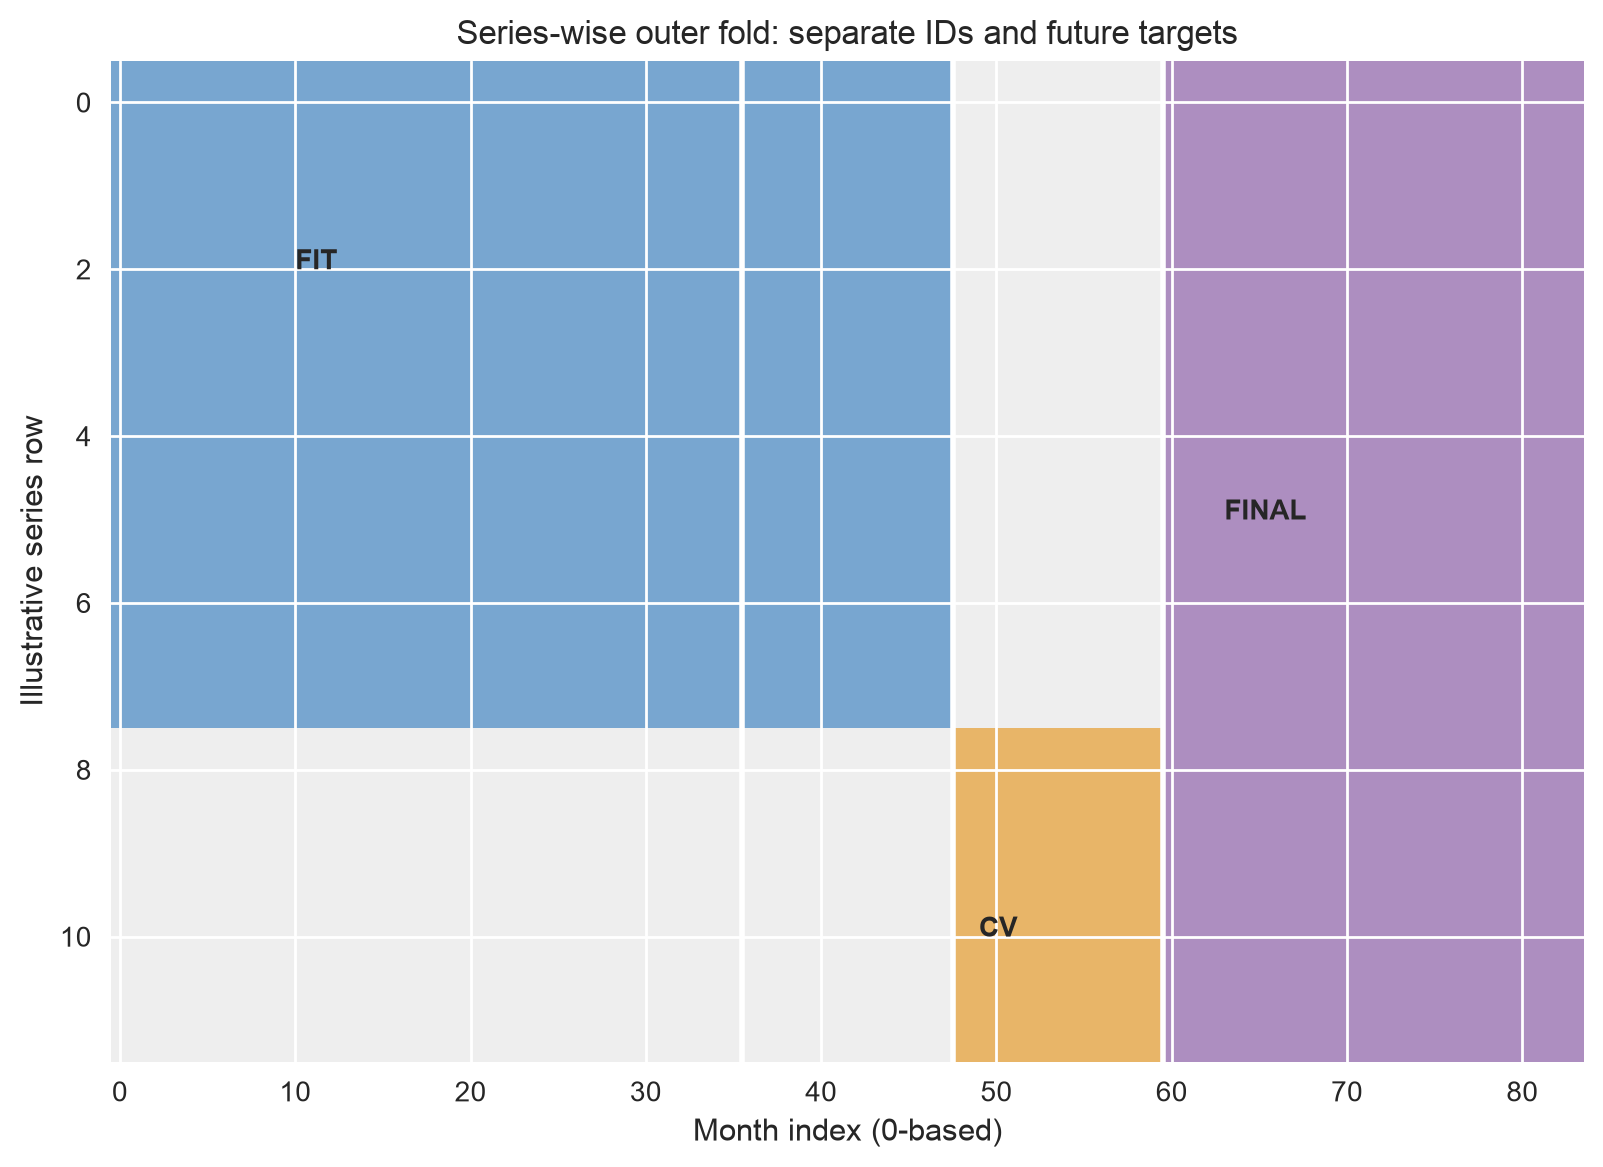

*Graph 02. Illustrative split mask, not a data-value heatmap.*

Blue history fits a model; orange targets belong to different series. Purple targets are untouched until all selectors are locked. Held-out series still supply past context when forecast.

In [11]:
manifest = publish_outputs(None, names, panel, "Two boundaries, one forecast", manifest)

The single split heatmap shows the two boundaries. Grey regions are unused for parameter fitting; held-out series still supply their past context at prediction time.

# Three global forecasters

A direct linear ridge map, a 32-unit MLP and an eight-unit GRU form the restricted candidate pool. Each has two regularization options. Neural fits use 40 full-batch Adam epochs at learning rate 0.01. Context-only centering/scaling is shared, with no series identity features. Seasonal naive repeats last year's 12 values as an external reference. It is not a candidate in the three-model selection oracle.

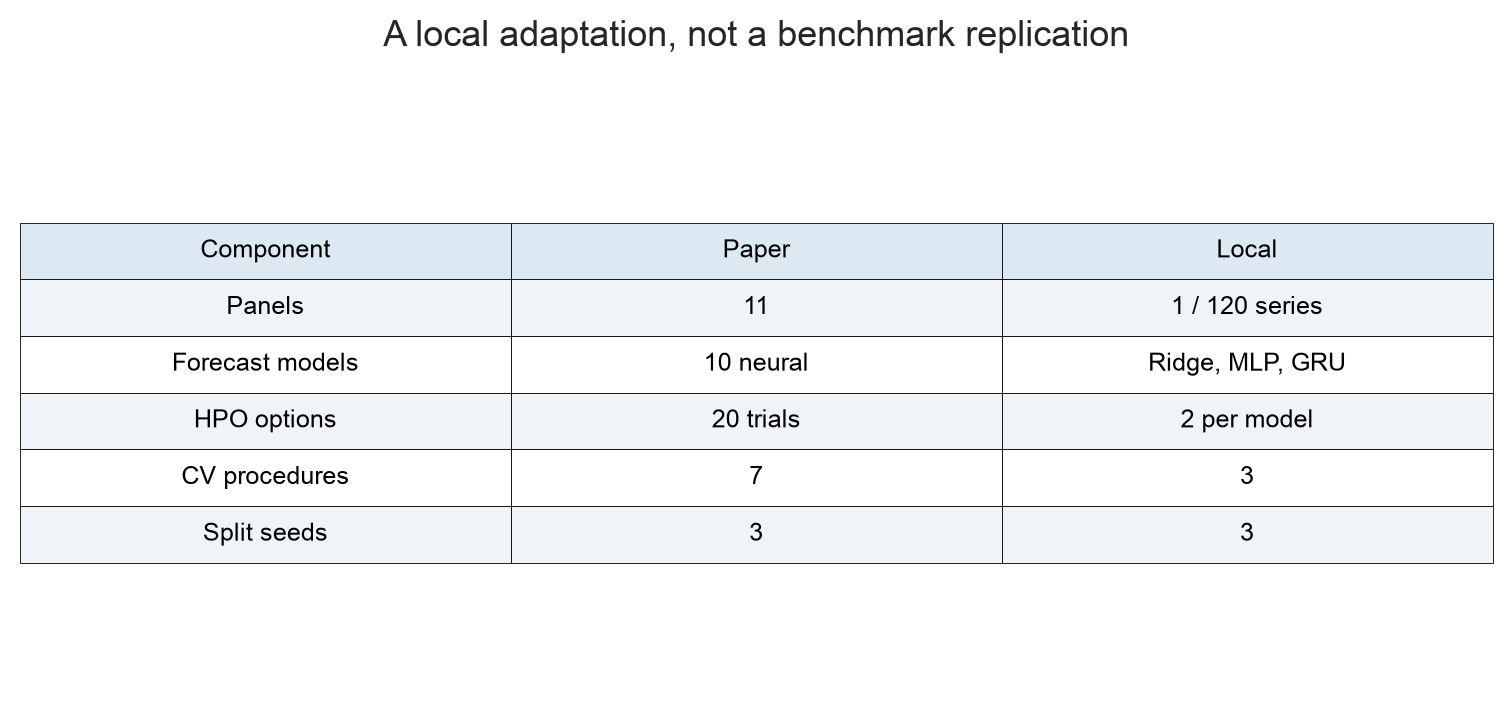

*Table 03. The local study deliberately narrows the paper's scope.*

The model pool and search are small enough for a laptop. Conclusions apply to this panel and candidate pool, not to the paper's full benchmark.

In [12]:
manifest = publish_outputs(None, names, panel, "Three global forecasters", manifest)

The scope table separates this local adaptation from the paper. The exact candidate definitions and training objective are explained above and implemented under Utils.

# Let the validation scheme choose

Every outer fold tunes each architecture on its own training series, using an inner temporal holdout. Final tuning uses a common temporal holdout on all known series; each final architecture is then refitted once through month 60. This common final pool is a deliberate departure from the paper's procedure-specific candidate pools. Selectors are locked before deployment scoring; no result-driven expansion of the candidate pool is allowed.

In [13]:
if CFG.mode == "live":
    CFG.run_folder = Path("runs") / CFG.execution_started_at.strftime("%Y%m%dT%H%M%S%f%z")
    run_experiment(panel, names, CFG.seeds, CFG.rhos, CFG.run_folder)
    json_write("latest-run.json", {"path": str(CFG.run_folder)})
else:
    if not (CFG.run_folder / "run.json").exists():
        raise FileNotFoundError("Replay evidence missing: supply the declared run folder")
result = analyze_run(CFG.run_folder)
assert result["ids"].tolist() == names.tolist()
for key, lock in result["locks"].items():
    print(key, lock["selected"])

rho0.7_seed123 {'Time holdout': 'Ridge', 'Series holdout': 'Ridge', 'Series 5-fold': 'MLP'}
rho0.7_seed456 {'Time holdout': 'MLP', 'Series holdout': 'MLP', 'Series 5-fold': 'MLP'}
rho0.7_seed789 {'Time holdout': 'Ridge', 'Series holdout': 'Ridge', 'Series 5-fold': 'Ridge'}
rho1.0_seed123 {'Time holdout': 'Ridge', 'Series holdout': 'Ridge', 'Series 5-fold': 'MLP'}
rho1.0_seed456 {'Time holdout': 'MLP', 'Series holdout': 'MLP', 'Series 5-fold': 'Ridge'}
rho1.0_seed789 {'Time holdout': 'Ridge', 'Series holdout': 'Ridge', 'Series 5-fold': 'Ridge'}


Live mode runs and preserves a new experiment. Replay reads genuine saved outputs, verifies the source/configuration/selection-lock hashes and recomputes metrics. Missing evidence raises an error. The selection lock names the architecture chosen by each validation procedure before any final scoring.

# Estimating error versus choosing a model

The denominator Q is the mean absolute seasonal difference over all known-series in-set observations (lag 12). It is fixed across folds and methods within a seed/rho condition, and must be positive. This is the paper's global-scaling variant, not standard per-series MASE. Final loss averages series, 13 origins and 12 horizons equally. MAPEE averages absolute estimation errors across three architectures; overoptimism counts underestimated model errors; selection hits and regret use the common final candidate pool.

In [14]:
checks = validate_evidence(CFG.run_folder, result)
print(checks)
print(f"{len(result['scores'])} procedure evaluations scored; the numbered table follows.")

{'status': 'passed', 'folds': 126, 'conditions': 6, 'scored_procedures': 18, 'source_hash_verified': True, 'selection_lock_hash_verified': True, 'series_and_temporal_boundaries': True, 'cv_losses_recomputed': True, 'cv_and_final_targets_match_source': True, 'global_denominators_recomputed': True}
18 procedure evaluations scored; the numbered table follows.


A missing unseen stratum at rho=1 is N/A, not a failed prediction or zero error. Three selection hits are out of three overlapping split seeds on one panel. Neither the oracle nor these denominators represent the paper's much larger benchmark.

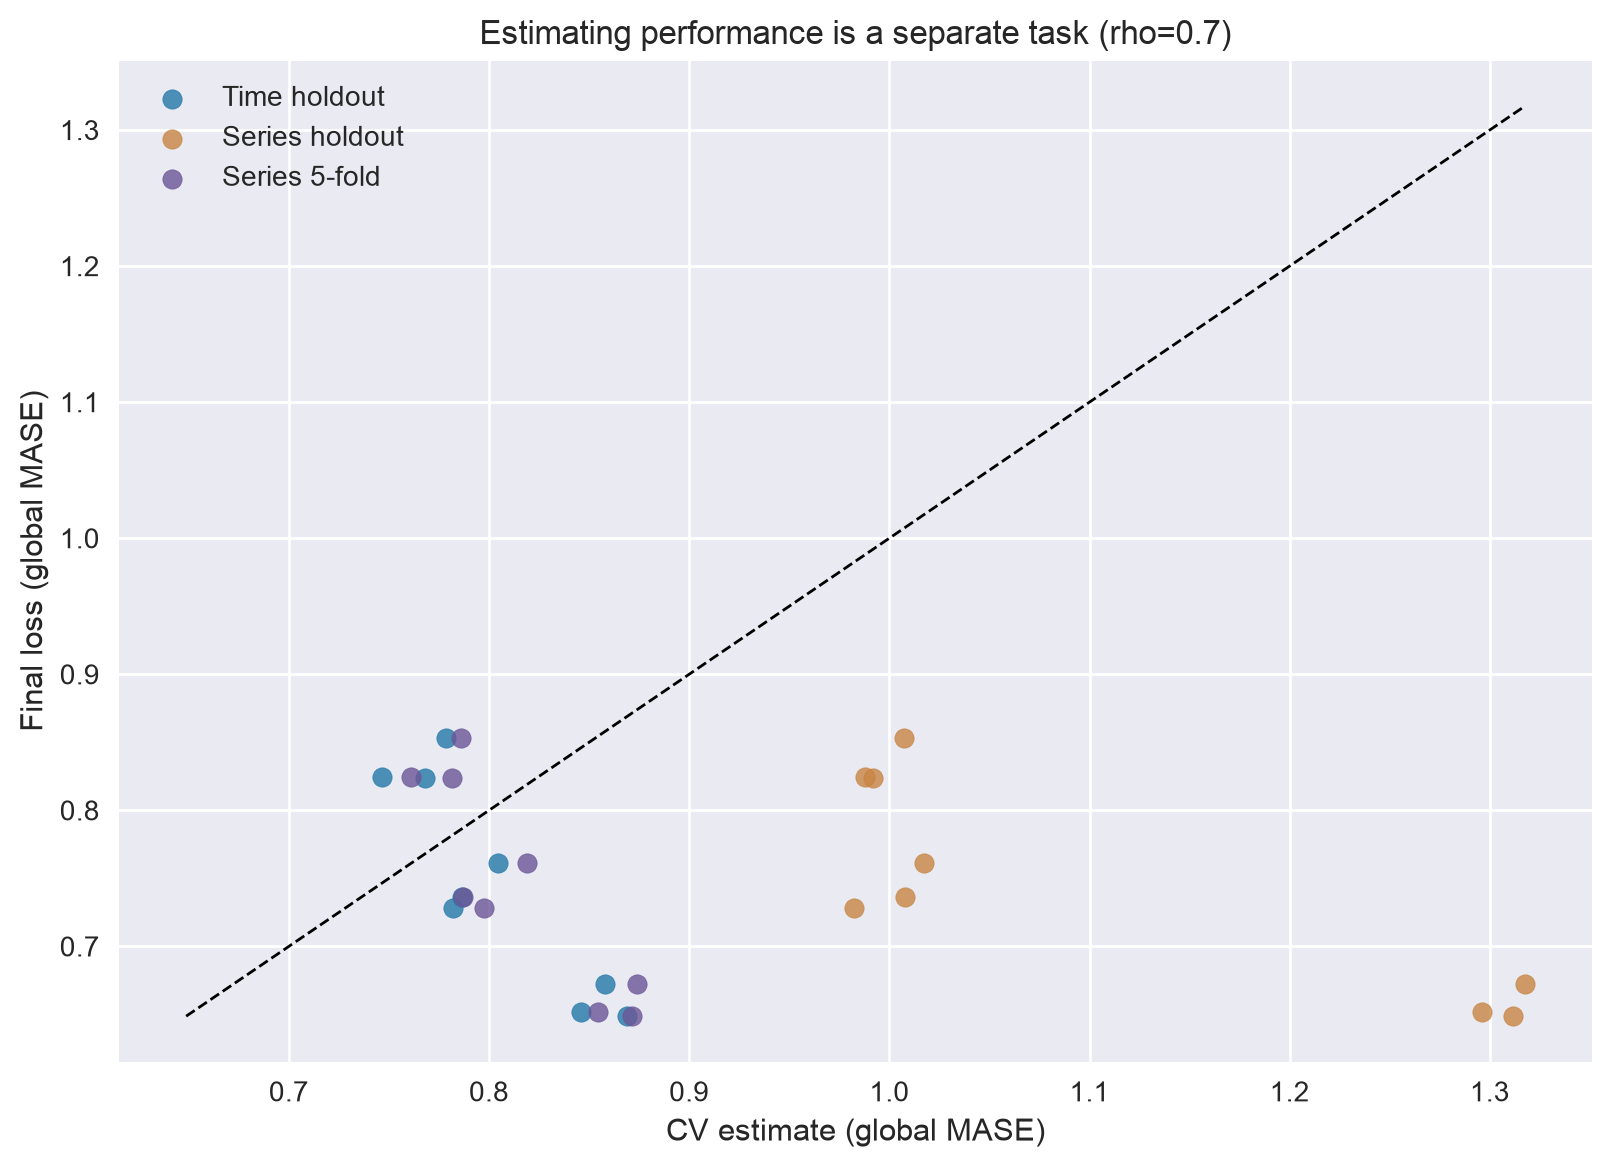

*Graph 04. Each dot is one architecture, split seed and validation procedure.*

The diagonal marks a perfect estimate. Above it, CV was optimistic. Closeness to the diagonal need not imply selecting the best model.

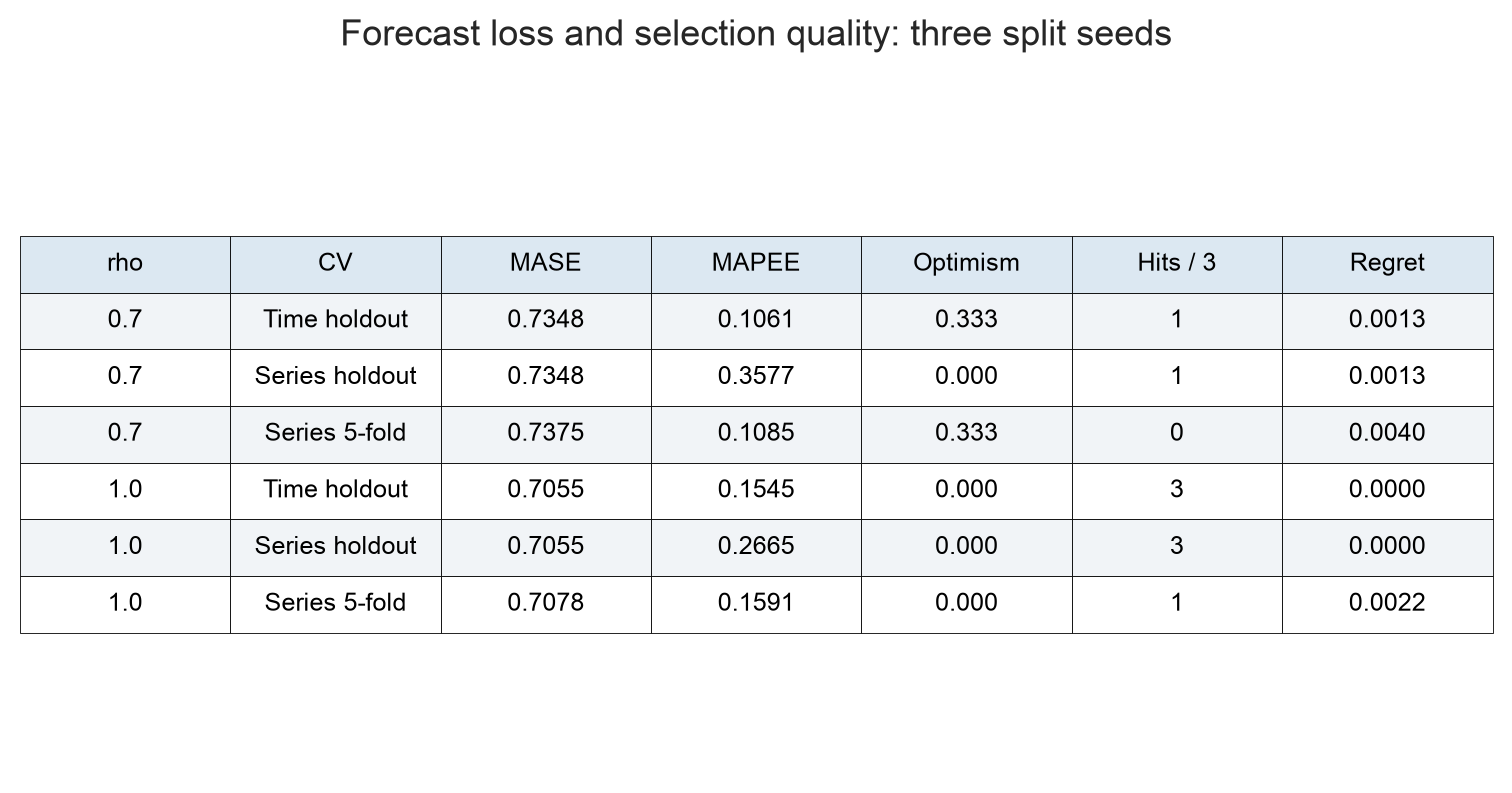

*Table 05. Mean scores on one panel; hits use three split seeds, not three datasets.*

Lower MASE, MAPEE and regret are better. Optimism is the fraction of the three candidate errors underestimated per seed. The oracle is restricted to the same final model pool.

In [15]:
manifest = publish_outputs(result, names, panel, "Estimating error versus choosing a model", manifest)

Graph 04 compares estimation with realized loss; Table 05 summarizes all five evaluation dimensions and downstream forecasting performance. These are complementary questions, not interchangeable measures of success.

# Familiar series and new arrivals

The primary contrast is selected-model future loss for series five-fold CV minus time holdout at rho=0.7; negative favors series CV. Its interval resamples series IDs while retaining all seed/origin/horizon contributions for each ID. Models, chosen architectures and Q stay fixed. This conditional interval excludes model-refitting uncertainty and dependence from shared calendar shocks.

In [16]:
print(json.dumps(result["primary"], indent=2))

{
  "delta": 0.0026674466431719224,
  "low": 0.0009726182858705886,
  "high": 0.004882509424772588,
  "series_clusters": 120,
  "bootstrap_reps": 2000,
  "interpretation": "conditional series bootstrap; fixed models/selectors/Q; shared calendar shocks and refitting uncertainty excluded"
}


The mean can be exactly zero if every validation scheme selects the same final model. That is an informative null outcome; the experiment must not search for a more favorable model pool after looking at the held-out results.

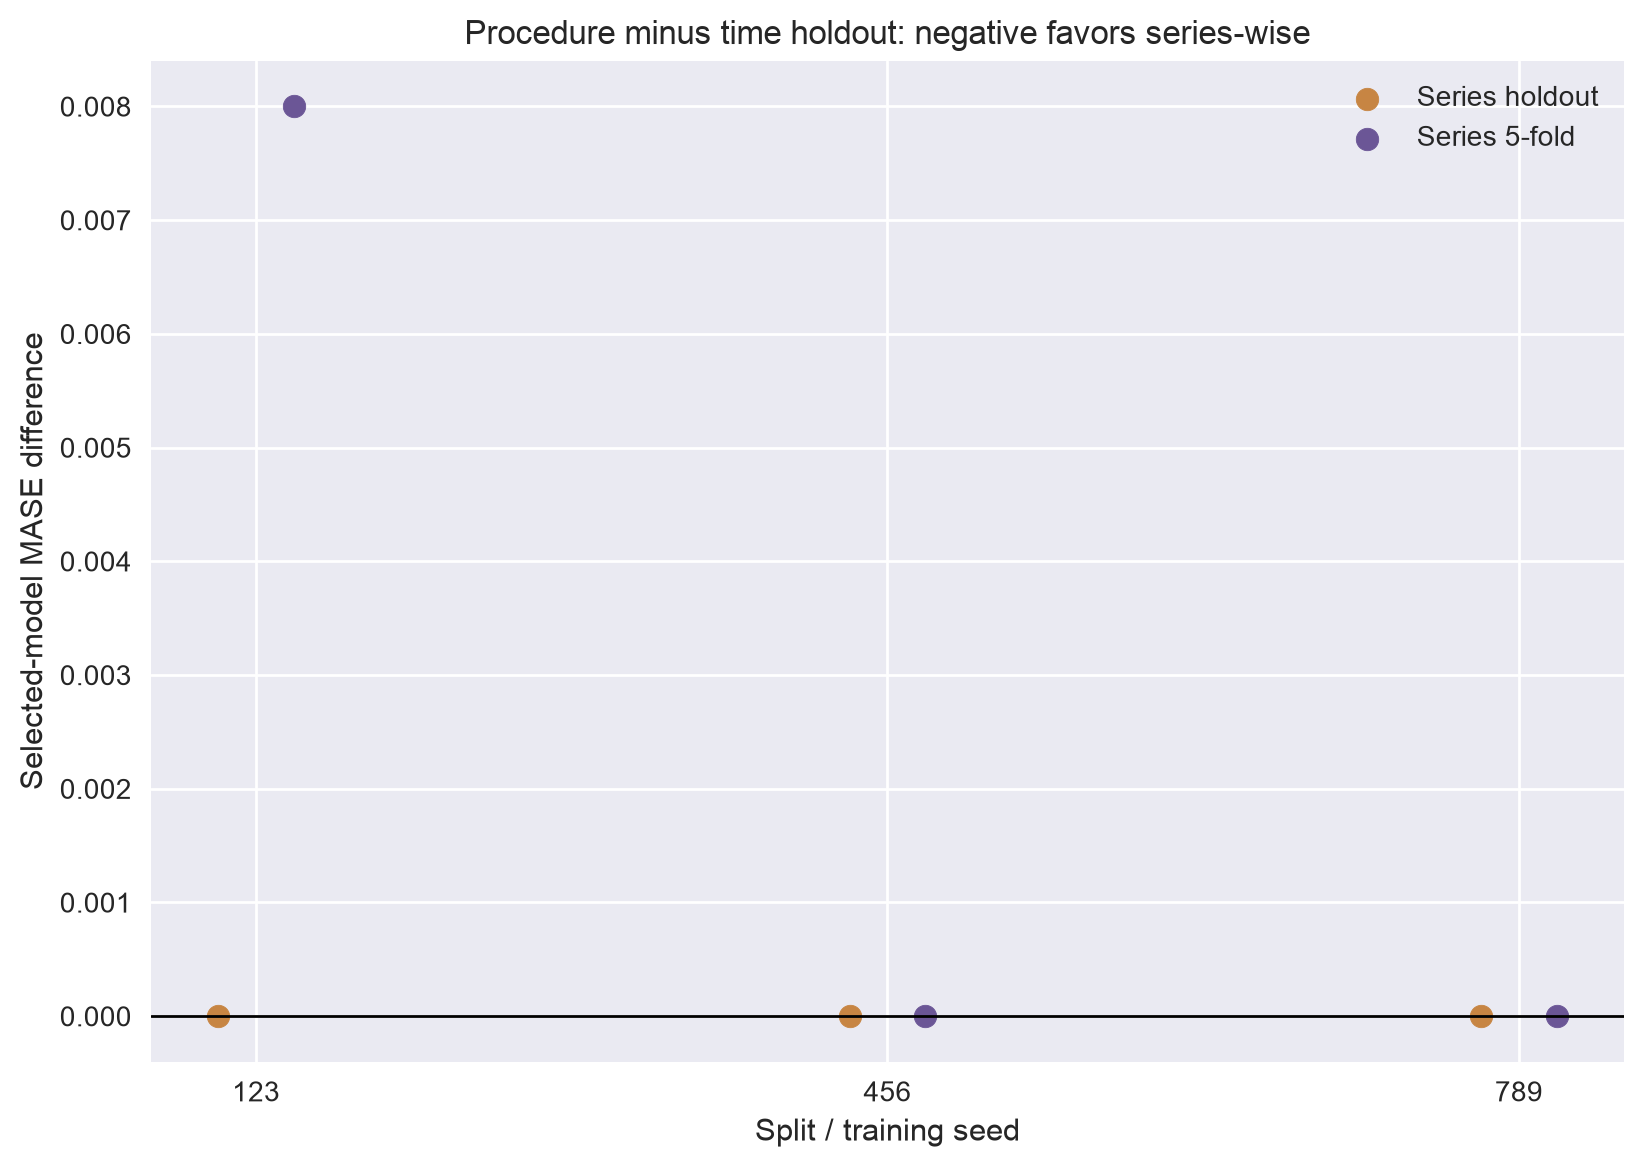

*Graph 06. Paired downstream differences at rho=0.7.*

Five-fold mean delta is 0.0027; its conditional series-bootstrap 95% interval is [0.0010, 0.0049]. Models, selectors and Q stay fixed. Shared shocks and refitting uncertainty are excluded.

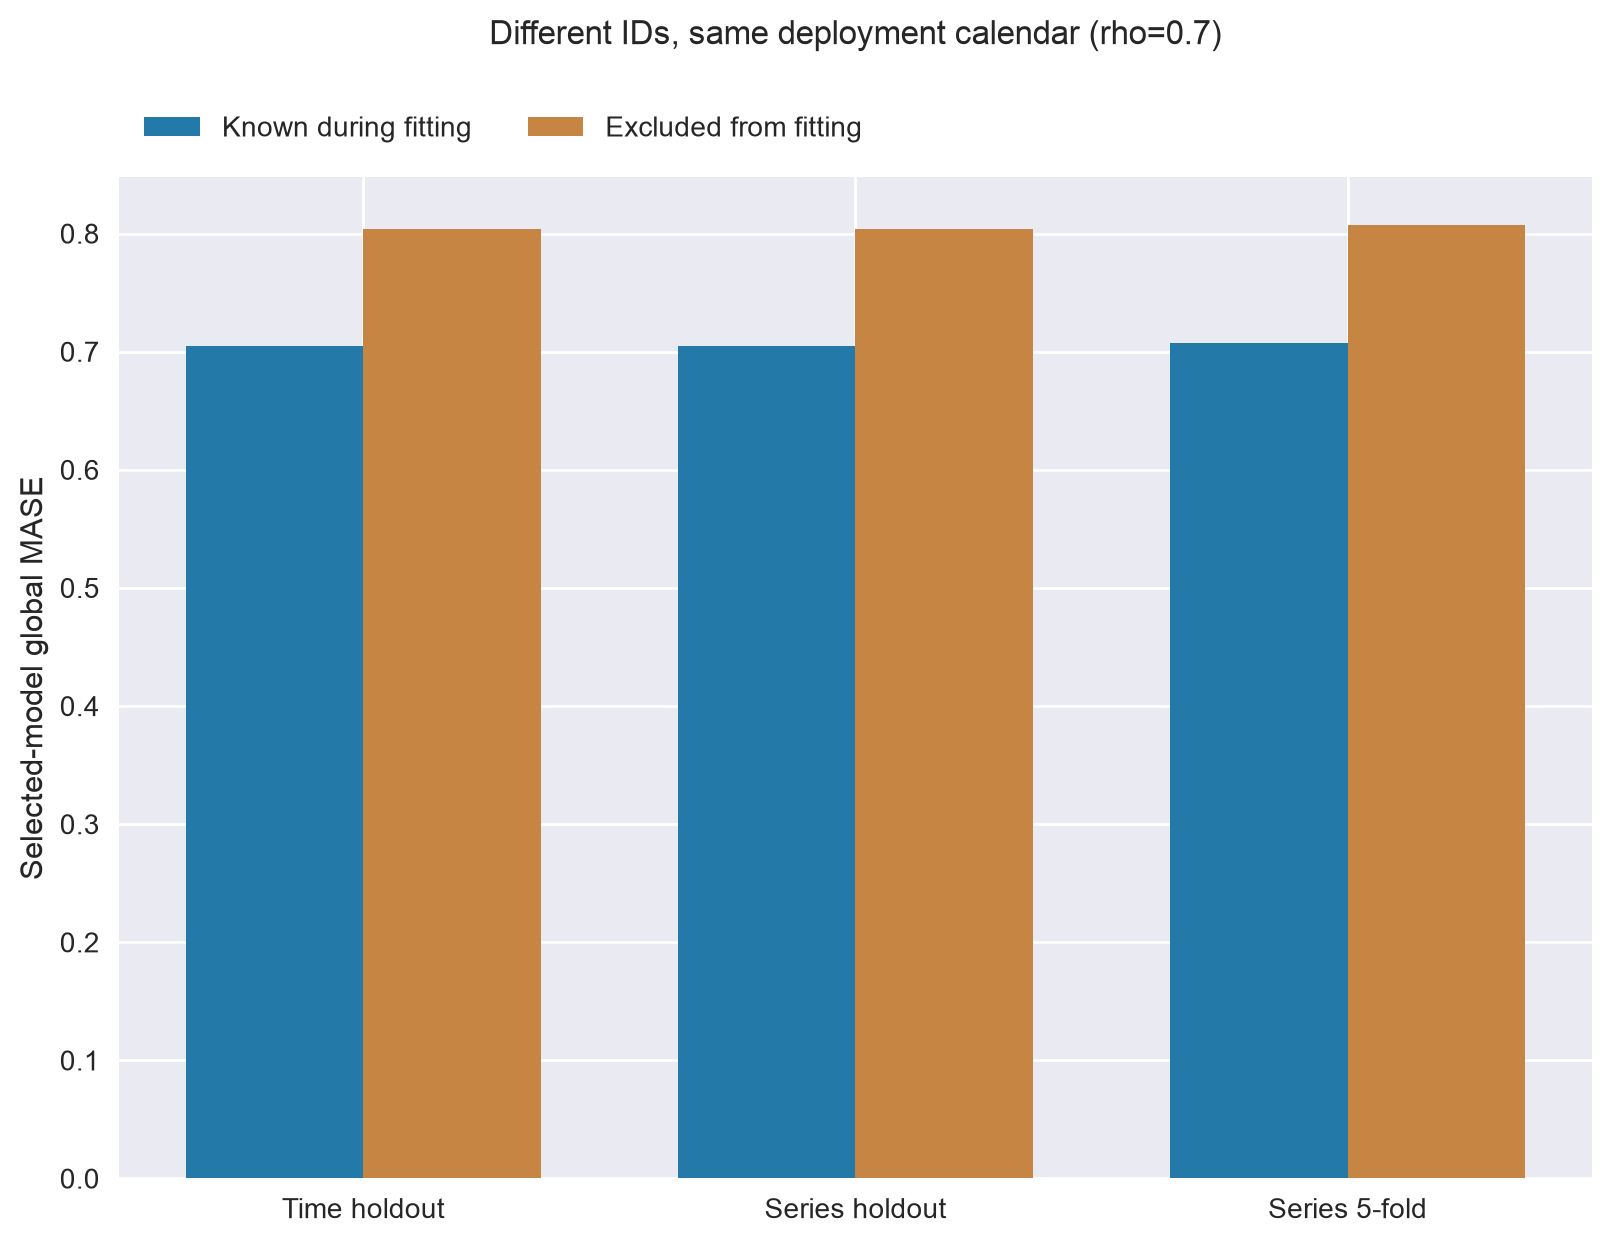

*Graph 07. Known and unseen series are scored separately with the same Q.*

The unseen stratum has higher mean loss in 1 of 3 time-holdout partitions (seeds: 456). The aggregate bars hide that variation. These different series groups do not identify a causal penalty from exclusion; all strata share the run's Q.

In [17]:
manifest = publish_outputs(result, names, panel, "Familiar series and new arrivals", manifest)

The paired-difference graph and the separate known/unseen graph answer different questions, so they are saved as two files. The interval conditions on the fitted experiment rather than refitting models during bootstrap resampling.

# What this experiment cannot establish

One medical-products panel and three small models cannot establish a universal ranking of CV methods, neural architectures or deployment performance. Time holdout and series CV differ in sample size and compute as well as series membership. Scratch training avoids pretrained-data contamination, but the published archive is a convenience sample. Observed context is available for new series, and common calendar shocks remain. Local CPU timings measure this run only.

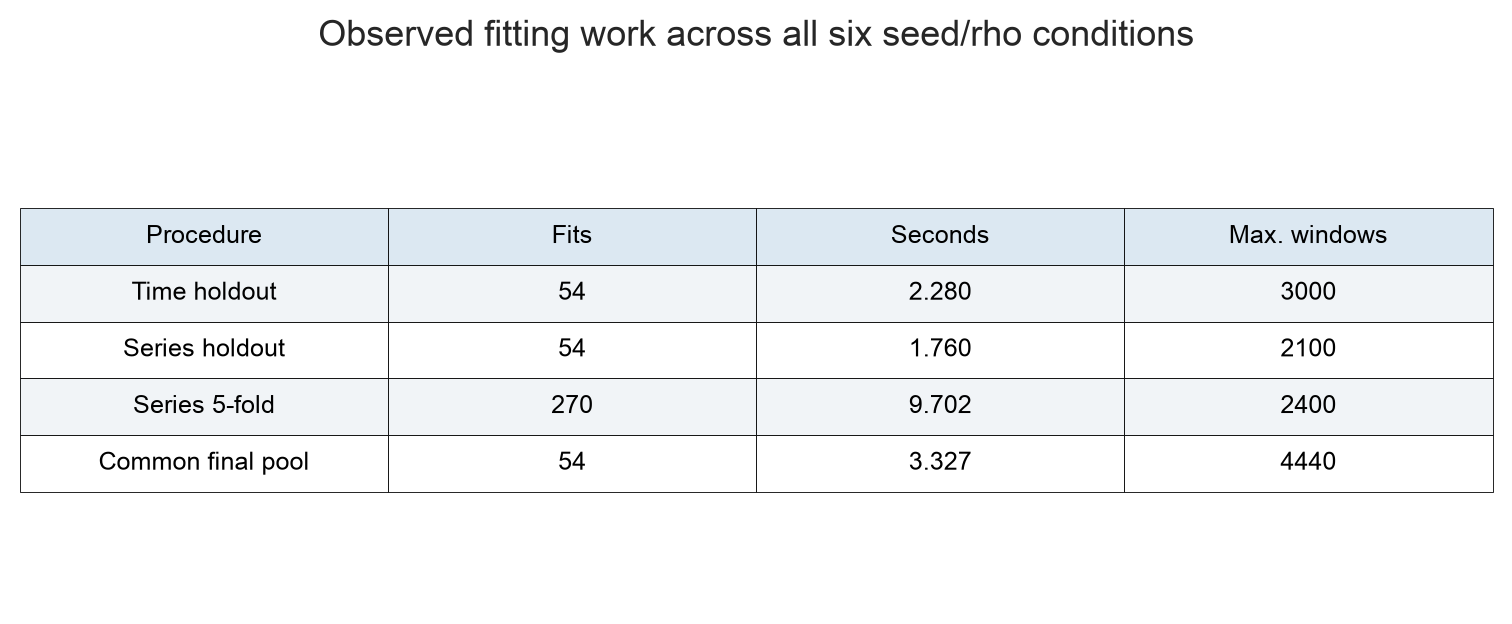

*Table 08. Logical fits and local CPU fitting time; common final models are trained once per condition.*

Five-fold CV spends more fits and trains on fewer series per outer fit. These are whole-procedure comparisons, not isolated measurements of the effect of series separation.

Exported 8 individually rendered assets from runs/20261106T225315732443+0100


In [18]:
manifest = publish_outputs(result, names, panel, "What this experiment cannot establish", manifest)
json_write("checks.json", checks)
print(f"Exported {len(manifest)} individually rendered assets from {CFG.run_folder}")

The final table reports local fitting work. The manifest now records the complete shared sequence, with each image displayed in its matching narrative section. CSV/JSON sidecars retain full numerical precision. Visual inspection remains necessary.

# Closing time

Validation has two jobs: estimating a model's error and choosing a useful model. This study reports both and accepts a null result. Choose validation to match the series population that deployment will encounter, then test that choice against genuinely held-out future observations. Consult the companion article for the measured interpretation and practical limits of this particular run.

In [19]:
p = result["primary"]
direction = "higher" if p["delta"] > 0 else ("lower" if p["delta"] < 0 else "the same")
display(Markdown(f"In this captured study, series five-fold CV produced **{direction}** selected-model loss than time holdout: mean global-MASE difference **{p['delta']:+.4f}** at rho=0.7. The conditional series-bootstrap interval is [{p['low']:.4f}, {p['high']:.4f}]. This is a result for one panel and a fixed fitted candidate pool."))

In this captured study, series five-fold CV produced **higher** selected-model loss than time holdout: mean global-MASE difference **+0.0027** at rho=0.7. The conditional series-bootstrap interval is [0.0010, 0.0049]. This is a result for one panel and a fixed fitted candidate pool.

This conclusion is generated from the current evidence so replay cannot silently retain a verdict from an older run. The interval's conditioning and the comparison's scope remain part of the interpretation.